## Test Day

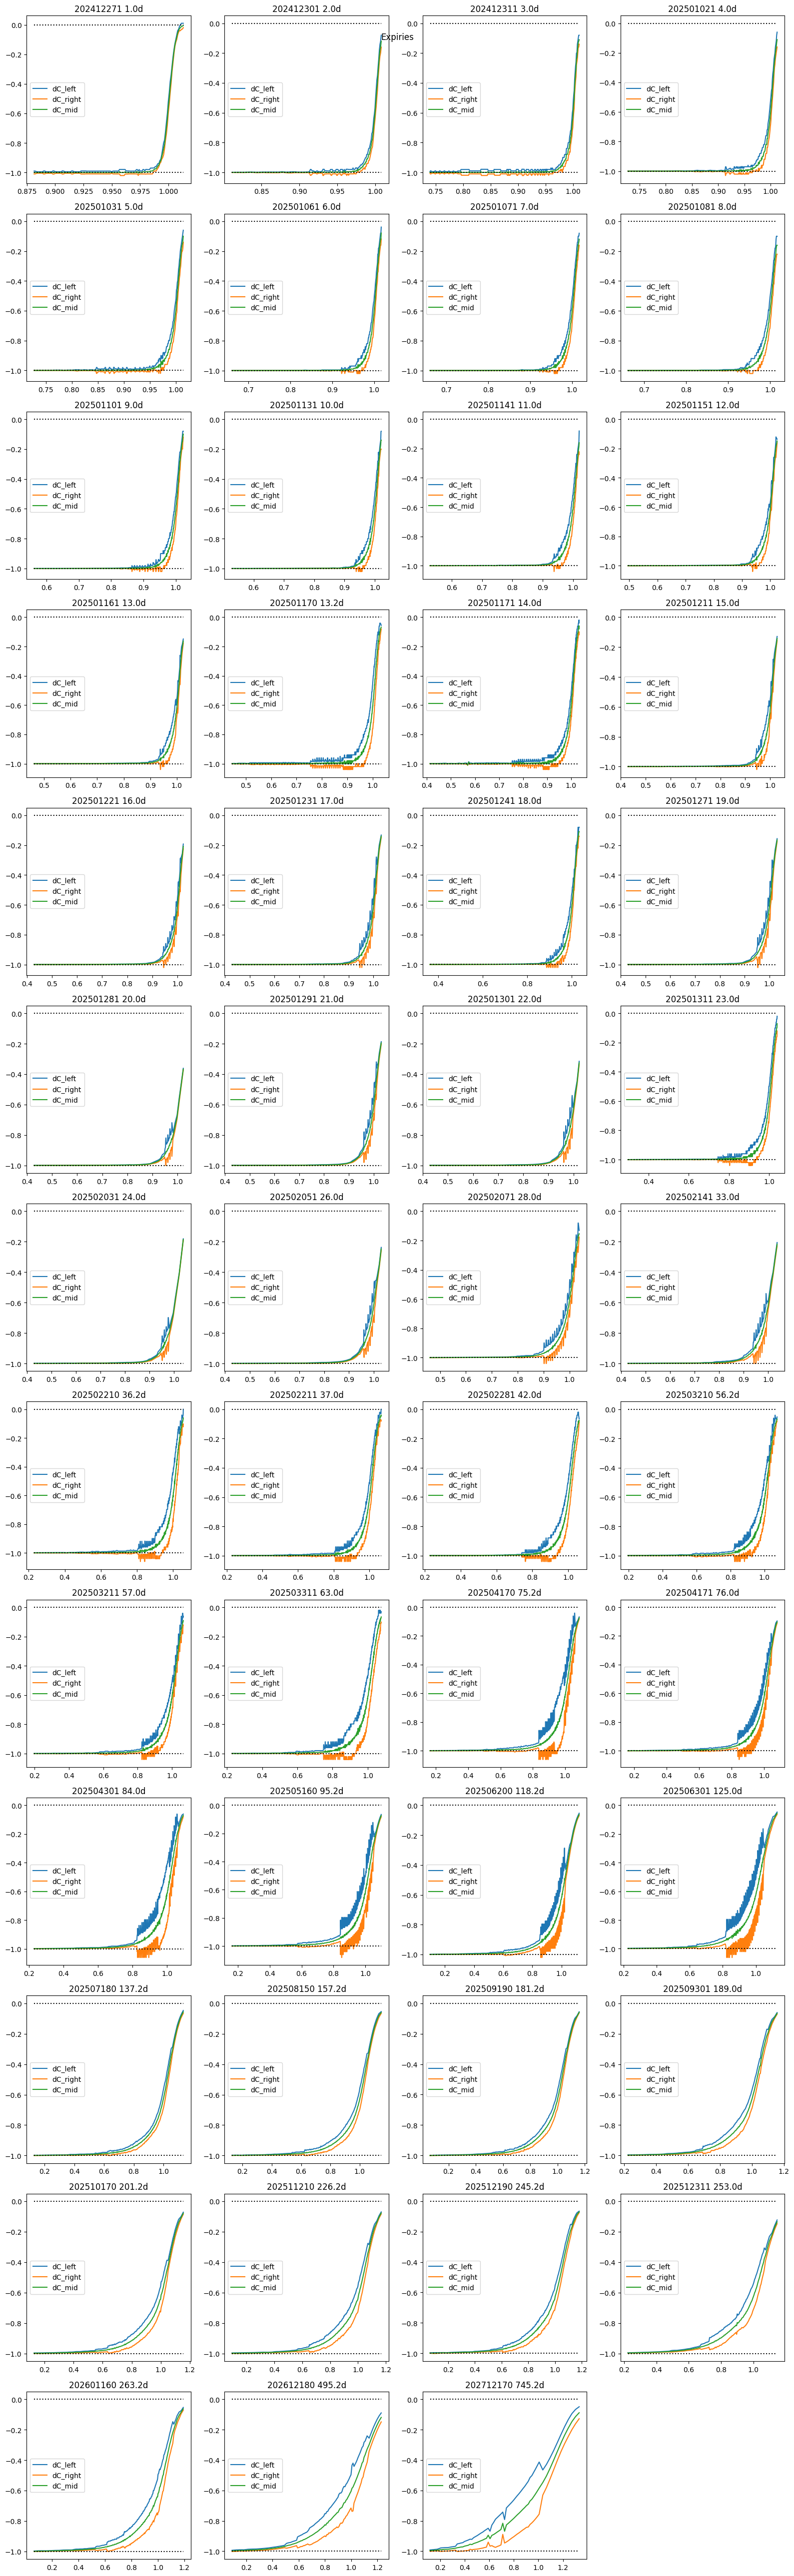

00: SPX 2024-12-26: Generating arb-free price surface.
01:   SPX 2024-12-26 expiry #0 1.0d: Could not hard fit with linear no-arbitrage -- using masked soft fit instead which is outside bid/ask for 4 of 69 options. This took 0.028s.
01:   SPX 2024-12-26 expiry #0 1.0d: Soft linear no-arbitrage fit succeeded within bid/ask. This took 0.011s.
01:   SPX 2024-12-26 expiry #0 1.0d: fit achived after removing 75 of 140 strikes.
01:   SPX 2024-12-26 expiry #1 2.0d: Could not hard fit with linear no-arbitrage -- using masked soft fit instead which is outside bid/ask for 4 of 116 options. This took 0.045s.
01:   SPX 2024-12-26 expiry #1 2.0d: Soft linear no-arbitrage fit succeeded within bid/ask. This took 0.016s.
01:   SPX 2024-12-26 expiry #1 2.0d: fit achived after removing 16 of 128 strikes.
01:   SPX 2024-12-26 expiry #2 3.0d: Could not hard fit with linear no-arbitrage -- using masked soft fit instead which is outside bid/ask for 30 of 261 options. This took 0.18s.
01:   SPX 2024-12-26 ex

,spot,spot_prev,date,ticker,call_symbol,put_symbol,call_opt_id,put_opt_id,is_american,is_am,...,pure_fit1_gamma,pure_fit1_vega,pure_fit1_theta,fitX_vol,pure_fitX_price,pure_fitX_delta,pure_fitX_dk,pure_fitX_gamma,pure_fitX_vega,pure_fitX_theta
0,6037.589844,6040.040039,2024-12-26,SPX,SPXW 241227C5320000,SPXW 241227P5320000,165310286,165310318,False,False,...,0.000000,0.000000,0.000000,0.010000,0.119328,1.000000,-1.000000,0.000000,0.000000,0.000000
1,6037.589844,6040.040039,2024-12-26,SPX,SPXW 241227C5325000,SPXW 241227P5325000,165310287,165310319,False,False,...,0.000000,0.000000,0.000000,0.010000,0.118500,1.000000,-1.000000,0.000000,0.000000,0.000000
2,6037.589844,6040.040039,2024-12-26,SPX,SPXW 241227C5330000,SPXW 241227P5330000,165310288,165310320,False,False,...,0.000000,0.000000,0.000000,0.010000,0.117673,1.000000,-1.000000,0.000000,0.000000,0.000000
3,6037.589844,6040.040039,2024-12-26,SPX,SPXW 241227C5340000,SPXW 241227P5340000,165310289,165310321,False,False,...,0.000000,0.000000,0.000000,0.010000,0.116017,1.000000,-1.000000,0.000000,0.000000,0.000000
4,6037.589844,6040.040039,2024-12-26,SPX,SPXW 241227C5350000,SPXW 241227P5350000,165204831,165204927,False,False,...,0.000000,0.000000,0.000000,0.010000,0.114362,1.000000,-1.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9141,6037.589844,6040.040039,2024-12-26,SPX,SPX 271217C8200000,SPX 271217P8200000,163911180,163911189,False,True,...,1.354361,0.501120,0.010602,0.125122,0.023716,0.214015,-0.156791,1.354361,0.501120,0.010602
9142,6037.589844,6040.040039,2024-12-26,SPX,SPX 271217C8400000,SPX 271217P8400000,149433116,149433122,False,True,...,1.230518,0.444899,0.009197,0.123417,0.018687,0.178781,-0.128764,1.231115,0.449309,0.009376
9143,6037.589844,6040.040039,2024-12-26,SPX,SPX 271217C8600000,SPX 271217P8600000,163911181,163911190,False,True,...,1.098637,0.393563,0.008061,0.119791,0.013773,0.142665,-0.101258,1.094386,0.387675,0.007852
9144,6037.589844,6040.040039,2024-12-26,SPX,SPX 271217C8800000,SPX 271217P8800000,149433117,149433123,False,True,...,0.955407,0.333192,0.006644,0.119303,0.010889,0.117872,-0.082135,0.962814,0.339676,0.006852


In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2024, 12, 26), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )
    with figure("Expiries", row_size=4, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d")

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            mids = (bids + asks) / 2.

            dC_left = ( asks[1:] - bids[:-1] ) / ( strikes[1:] - strikes[:-1] )
            dC_right = ( asks[:-1] - bids[1:] ) / ( strikes[:-1] - strikes[1:] )
            dC_mid = ( mids[1:] - mids[:-1] ) / ( strikes[1:] - strikes[:-1] )

            ax.plot(strikes[1:], dC_left, label="dC_left")
            ax.plot(strikes[1:], dC_right, label="dC_right")
            ax.plot(strikes[1:], dC_mid, label="dC_mid")
            ax.plot(strikes[1:], strikes[1:]*0-1., ":", color="black")
            ax.plot(strikes[1:], strikes[1:]*0, ":", color="black")
            ax.legend()

    arb_free = MkArbFree()
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()